# P6：冻结方案的最终评估

本 Notebook 只读取已归档的最终预测、指标及研究凭据，不重新训练、不重新访问原始 8 月目标，也不根据测试结果返回调参。主指标候选可能是朴素基线；模型选择必须忠于开发结果。

In [1]:
from pathlib import Path
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'scripts/build_features.py').is_file()), Path('D:\\airline-delay'))
RUN_DIR = ROOT / 'experiments/runs/R0028'
OUTPUT_RUN_DIR = ROOT / 'experiments/runs/R0028'
NOTEBOOK_DIR = ROOT / 'notebooks'
RQ2_EDA_RUN_DIR = ROOT / 'experiments/runs/R0028'
MODEL_RUNS = []
RQ1_RUN_DIR = ROOT / 'experiments/runs/R0028'

In [2]:
from pathlib import Path
import hashlib
import json
import os
from urllib.parse import quote
import pandas as pd
from IPython.display import display, Markdown, Image

def notice(text):
    display(Markdown(text))

def link_file(path):
    relative = os.path.relpath(path, NOTEBOOK_DIR).replace(chr(92), "/")
    return f"[{path.name}]({quote(relative, safe='/.:')})"

def archived_json(name, base=None, show=True, keys=None):
    path = (RUN_DIR if base is None else base) / name
    if not path.is_file():
        notice(f"**未归档：{path.name}**（{path.parent.name}）。")
        return None
    value = json.loads(path.read_text(encoding="utf-8-sig"))
    if show:
        notice(f"**{link_file(path)}**")
        selected = value if keys is None else {key: value.get(key, "未归档该字段") for key in keys}
        notice("```json\n" + json.dumps(selected, ensure_ascii=False, indent=2) + "\n```")
    return value

def archived_table(name, base=None, limit=100, filters=None):
    path = (RUN_DIR if base is None else base) / name
    if not path.is_file():
        notice(f"**未归档：{path.name}**（{path.parent.name}）。")
        return None
    value = pd.read_csv(path, float_precision="round_trip")
    full_n = len(value)
    if filters:
        for column, selected in filters.items():
            if column not in value:
                notice(f"**{path.name} 未归档字段：{column}；未显示该筛选。**")
                return value
            value = value.loc[value[column].eq(selected)]
    notice(f"**{link_file(path)}**：完整表 {full_n:,} 行；当前条件 {len(value):,} 行。")
    shown = value if limit is None else value.head(limit)
    with pd.option_context("display.max_columns", None, "display.max_rows", None if limit is None else max(limit, 10)):
        display(shown)
    if len(shown) < len(value):
        notice(f"上方仅展示前 {len(shown):,} 行，完整结果见该归档 CSV。")
    return value

def archived_image(name, base=None):
    path = (RUN_DIR if base is None else base) / name
    if not path.is_file():
        notice(f"**未归档图：{path.name}**。")
        return False
    notice(f"**{link_file(path)}**")
    display(Image(filename=str(path)))
    return True

def archive_matches(pattern, base=None, kind="table", limit=60):
    base = RUN_DIR if base is None else base
    paths = sorted(base.glob(pattern))
    if not paths:
        notice(f"**未归档：{base.name}/{pattern}**。")
    for path in paths:
        if kind == "json":
            archived_json(str(path.relative_to(base)), base=base)
        elif kind == "image":
            archived_image(str(path.relative_to(base)), base=base)
        else:
            archived_table(str(path.relative_to(base)), base=base, limit=limit)

def single_flight_eda(base):
    notice(f"**完整单航段 EDA 来源：{base.name}**")
    archived_json("tables/eda_complete_summary.json", base=base)
    for name in ["single_flight_delay_stats.csv", "single_flight_operations.csv", "airline_aircraft_coverage.csv",
                 "airline_aircraft_models.csv", "airport_activity.csv", "rq2_weather_missing_coverage.csv"]:
        archived_table("tables/" + name, base=base)
    for name in ["monthly_delay_quantiles.png", "delay_sign_counts.png"]:
        archived_image("figures/" + name, base=base)

def model_structure_explanations(base):
    summaries = sorted(base.glob("**/explain_summary.json"))
    if not summaries:
        notice(f"**未归档结构解释摘要：{base.name}。**")
    for summary_path in summaries:
        source = summary_path.parent
        summary = json.loads(summary_path.read_text(encoding="utf-8-sig"))
        notice(f"### 系数、截距与树路径：{source.name}（{base.name}）")
        coefficients = source / "explain_coefficients.csv"
        has_linear_coefficients = False
        if coefficients.is_file():
            notice(f"**{link_file(coefficients)}**：完整编码系数表可下载。")
            table = pd.read_csv(coefficients, float_precision="round_trip")
            if table.empty:
                notice("系数表为空。树模型没有线性 coef_；应结合下面的已归档树路径阅读，不生成替代系数。")
            elif not {"fold", "encoded_feature", "coefficient"}.issubset(table):
                notice("系数表未归档完整 fold/encoded_feature/coefficient 字段，不能分类展示。")
            else:
                has_linear_coefficients = True
                numeric = table.loc[table.encoded_feature.astype(str).str.startswith("numeric__")]
                categorical = table.loc[~table.encoded_feature.astype(str).str.startswith("numeric__")]
                notice(f"**numeric__ 数值特征系数：{len(numeric):,} 行**（预处理后的编码/缩放单位）。")
                with pd.option_context("display.max_columns", None, "display.max_rows", None):
                    display(numeric)
                notice(f"**其他编码系数：共 {len(categorical):,} 行，按归档行序仅显示前 12 行**。类别系数依赖参考类别，数值系数使用缩放后输入；不能把绝对系数大小直接当重要性排名，也不能解释为因果效应。")
                display(categorical.head(12))
        else:
            notice("**未归档 explain_coefficients.csv**。树模型不适用线性系数；缺失文件本身不证明已完成线性解释。")
        intercepts = archived_table("explain_intercepts.csv", base=source, limit=None)
        if intercepts is not None and intercepts.empty:
            notice("截距表为空；树模型没有线性截距项，不补造截距。")
        paths = sorted(source.glob("explain_*_tree_paths.txt"))
        if not paths:
            if has_linear_coefficients:
                notice("该归档提供线性系数。OLS 没有树分裂路径，树路径不适用。")
            elif summary.get("tree_path_files"):
                notice("**摘要列有树路径文件，但当前解释目录未归档对应 txt；不能展示替代路径。**")
            else:
                notice("未归档树路径；是否适用应结合该模型类型与解释摘要判断。")
        for path in paths:
            lines = path.read_text(encoding="utf-8-sig").splitlines()
            notice(f"**{link_file(path)}**：完整文本 {len(lines):,} 行，下面最多展示前 120 行。DT 为一棵树，RF 为归档的前 3 棵，路径截于深度 3。阈值处于编码/缩放输入空间，不能直接按原始分钟或距离解读。RF 的前 3 棵、深度 3 截断仅为结构示例，不代表整个森林的全局解释。")
            notice("```text\n" + "\n".join(lines[:120]) + "\n```")
            if len(lines) > 120:
                notice("展示文本已截断，完整路径见上方归档下载链接。")

def rq1_reference(base):
    value = archived_json("rq1_standardized/frozen_reference.json", base=base,
                          keys=["schema_version", "frozen_on", "supported", "protocol", "interpretation"])
    if value is None:
        return
    notice("**冻结的机场集合 A 与共同主分层 C**")
    display(pd.DataFrame({"AirportID_in_A": value.get("airport_ids", [])}))
    display(pd.DataFrame({"master_cell_in_C": value.get("master_cells", [])}))
    rows = []
    for threshold, ref in value.get("references", {}).items():
        cells, weights = ref.get("cells", []), ref.get("weights", [])
        counts = ref.get("development_counts", [None] * len(cells))
        if len(cells) != len(weights) or len(cells) != len(counts):
            notice(f"**{threshold} 的冻结 cells/weights/counts 长度不一致，不能构造权重表。**")
            continue
        rows.extend({"threshold": threshold, "cell": cell, "weight_w": weight, "development_count": count}
                    for cell, weight, count in zip(cells, weights, counts))
    notice("**分阈值条件化的固定参考权重 w**")
    display(pd.DataFrame(rows))
    if not value.get("supported", False):
        notice("**该冻结参考未形成足够共同支持；不补零，不强行排序。**")

def model_comparison_runs():
    records, protocols = [], []
    if not MODEL_RUNS:
        notice("**未归档模型运行列表：本次未指定 model_runs，不自动选择其他实验。**")
        return
    for source in MODEL_RUNS:
        notice(f"### 模型归档：{source.name}")
        outer = archived_json("manifest.json", base=source, show=False)
        if outer is not None:
            notice(f"运行状态：**{outer.get('status', '未归档状态')}**。")
            if outer.get("config", {}).get("mode") == "final":
                notice("**这是最终测试归档，不纳入开发模型比较。**")
                continue
        manifest = archived_json("model_manifest.json", base=source, show=False)
        if manifest is None:
            continue
        if manifest.get("development_only") is False:
            notice("**这是最终测试模型，不纳入 P5 开发比较。**")
            continue
        notice("```json\n" + json.dumps({key: manifest.get(key, "未归档该字段") for key in
            ["feature_group", "model_name", "model_type", "models", "features", "categorical_features", "numeric_features",
             "model_params", "effective_preprocessing", "evaluation_rows", "evaluation_ids_sha256", "split_sha256"]}, ensure_ascii=False, indent=2) + "\n```")
        metrics = archived_table("metrics.csv", base=source, filters={"group": "all"}, limit=None)
        if metrics is not None and {"fold", "model", "mae", "rmse", "n"}.issubset(metrics):
            for row in metrics.loc[metrics.fold.eq("overall")].to_dict("records"):
                records.append({"run_id": source.name, "model": row["model"], "n": row["n"], "mae": row["mae"], "rmse": row["rmse"],
                                "feature_group": manifest.get("feature_group"), "model_type": manifest.get("model_type"),
                                "evaluation_ids_sha256": manifest.get("evaluation_ids_sha256"), "split_sha256": manifest.get("split_sha256")})
            protocols.append((manifest.get("evaluation_ids_sha256"), manifest.get("split_sha256")))
        archive_matches("**/comparison_metrics.csv", base=source, limit=None)
        archive_matches("**/comparison.json", base=source, kind="json")
        archive_matches("**/comparison_error_differences.png", base=source, kind="image")
    if records:
        notice("### 所指定开发运行的整体指标")
        combined = pd.DataFrame(records)
        display(combined)
        comparable = bool(protocols) and all(a and b for a, b in protocols) and len(set(protocols)) == 1
        if comparable:
            notice("这些归档声明相同的评估 ID 与切分哈希；完整逐行标签/时间一致性及配对区间仍以各 comparison.json/CSV 为证据。")
            for baseline in ["training_mean", "training_median", "carry_forward"]:
                values = combined.loc[combined.model.eq(baseline), "mae"]
                if len(values) and values.max() - values.min() <= 1e-10:
                    combined[f"delta_MAE_vs_{baseline}"] = combined.mae - values.iloc[0]
                elif len(values):
                    notice(f"**同名 {baseline} 的 MAE 在归档间不一致；不合并为单一参照。**")
            display(combined)
            notice("增量表为候选 MAE 减参照 MAE：正值表示更差；不是配对置信区间，也不是因果效应。")
        else:
            notice("**评估 ID/切分哈希缺失或不一致：上表仅陈列各轮结果，不据此判断模型改善。**")

def rq1_reference_identity(base):
    copied = base / "rq1_standardized/frozen_reference.json"
    if not copied.is_file():
        notice("**未归档最终 RQ1 的冻结参考副本，无法核对参考身份。**")
        return
    observed = hashlib.sha256(copied.read_bytes()).hexdigest()
    complete = archived_json("rq1_complete_summary.json", base=base, show=False)
    expected = None if complete is None else complete.get("frozen_reference_sha256")
    evidence = {"copied_reference_sha256": observed, "complete_summary_sha256": expected,
                "matches_complete_summary": observed == expected if expected else "未归档待比较 SHA"}
    config = archived_json("config.json", base=base, show=False)
    origin = None if config is None else config.get("rq1_frozen_reference_path")
    if origin:
        original = Path(origin)
        original = original if original.is_absolute() else ROOT / original
        if original.is_file():
            original_sha = hashlib.sha256(original.read_bytes()).hexdigest()
            evidence.update(development_reference_path=origin, development_reference_sha256=original_sha,
                            matches_development_reference=original_sha == observed)
        else:
            evidence["development_reference_identity"] = "源参考路径未归档/不可用，未额外声明相同"
    else:
        evidence["development_reference_identity"] = "未归档开发参考源路径"
    display(pd.json_normalize(evidence))
    if evidence.get("matches_complete_summary") is False or evidence.get("matches_development_reference") is False:
        notice("**参考 SHA 不一致：不能据此宣称最终沿用了相同冻结参考。**")

notice(f"**阅读归档：{RUN_DIR.name}**。所有单元仅读取已保存结果，不训练、不重算研究样本或选择参数。")


**阅读归档：R0028**。所有单元仅读取已保存结果，不训练、不重算研究样本或选择参数。

## 1. 冻结选择与执行配置

冻结文件包含开发选择理由、预先指定的主模型、最佳学习模型的特征/算法/参数、预处理和评估协议。最终一次同时报告冻结学习模型与均值/中位数/carry-forward；主模型字段与学习模型名称分开记录。冻结 SHA 与源码/数据 SHA 在正式访问前核对。

In [3]:
freeze = archived_json("model_selection.json", show=False)
if freeze is not None:
    for key in ["schema_version", "status", "frozen_at_utc", "selection", "primary_model_name", "payload_sha256"]:
        notice("```json\n" + json.dumps({key: freeze.get(key, "未归档该字段")}, ensure_ascii=False, indent=2) + "\n```")
    notice("**冻结科学配置**")
    display(pd.json_normalize(freeze.get("config", {})))
    notice("**冻结评估协议**")
    notice("```json\n" + json.dumps(freeze.get("protocol", {}), ensure_ascii=False, indent=2) + "\n```")
archived_json("final_effective_config.json")
archived_json("final_result.json", keys=["mode", "primary_model_name", "model_name", "models", "evaluation_rows",
              "freeze_manifest_sha256", "freeze_payload_sha256", "access_ledger_path", "utc_boundary_audit", "primary_metric"])

```json
{
  "schema_version": 1
}
```

```json
{
  "status": "frozen"
}
```

```json
{
  "frozen_at_utc": "2026-10-24T03:06:18.048702+00:00"
}
```

```json
{
  "selection": {
    "selected_run_id": "R0025",
    "reason": "Registered family minima and sequential practical/monthly-stability promotion, followed by minimum pooled MAE against all three baselines",
    "selection_sha256": "4221e662267d46cbaa1182f8cf3645470a45570391583920336c5d7545563544",
    "actual_git_commit": "33f98c7054f801a6767c323b5f483cc99ec65ce2",
    "choice_files": [
      {
        "path": "experiments/runs/R0027/selection/baseline_monthly_metrics.csv",
        "sha256": "388279b44fd2b4a6df7c5e78196d8861a89155c934f50ff76d2133c2cf367bb3",
        "bytes": 912
      },
      {
        "path": "experiments/runs/R0027/selection/candidate_monthly_metrics.csv",
        "sha256": "a878075aaf62ec7ff96dd88721c51b288ebdbe4686958fe2b1e51a416ea69323",
        "bytes": 2001
      },
      {
        "path": "experiments/runs/R0027/selection/candidates.csv",
        "sha256": "a4db14306cbe3edfd968b2f3ff8f7a37a420fb17103434793fffd11f292c8ef1",
        "bytes": 3131
      },
      {
        "path": "experiments/runs/R0027/selection/paired_intervals.csv",
        "sha256": "73baf0048f70cded54a44b37ce6bad20468a1322362410d3151e8e8ecc3be8f4",
        "bytes": 2504
      },
      {
        "path": "experiments/runs/R0027/selection/promotion_decisions.csv",
        "sha256": "eb9ab4af5bbbd225d3139d4e9bace982733b0f762511e8e47dc8b23ba92b35d4",
        "bytes": 474
      },
      {
        "path": "experiments/runs/R0027/selection/model_selection_decision.json",
        "sha256": "cd2e7d80390374e87e9e55c38802ead27990fe6e4c12e6f00cddea6d869cb913",
        "bytes": 26636
      }
    ],
    "feature_source_run_id": "R0017"
  }
}
```

```json
{
  "primary_model_name": "rf_d16_l50"
}
```

...

**[final_effective_config.json](../experiments/runs/R0028/final_effective_config.json)**

```json
{
  "data_id": "D0003",
  "connection_path": "processed/D0003/flight_connections.csv.gz",
  "data_manifest_path": "processed/D0003/data_manifest.json",
  "feature_group": "G4B",
  "model_name": "rf_d16_l50",
  "model_type": "random_forest",
  "include_baselines": true,
  "threads": 24,
  "seed": 42,
  "linear_tolerance": 1e-06,
  "preprocessing": {
    "drop": "first",
    "min_frequency": 20
  },
  "primary_metric": "sample-weighted pooled validation MAE in minutes",
  "prediction_rule": "clip all predictions at zero",
  "split_rule": "UTC half-open prediction windows; training label_time strictly before cutoff",
  "sample_interpretation": "Retrospective prediction conditional on valid observed same-tail scheduled-adjacent completed connections",
  "weather_manifest_path": "processed/W0002/data_manifest.json",
  "noaa_backfill": false,
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "model_params": {
    "max_depth": 16,
    "max_features": 0.5,
    "min_samples_leaf": 50,
    "n_estimators": 200,
    "random_state": 42
  },
  "prediction_threads": 1
}
```

**[final_result.json](../experiments/runs/R0028/final_result.json)**

```json
{
  "mode": "final",
  "primary_model_name": "rf_d16_l50",
  "model_name": "rf_d16_l50",
  "models": [
    "training_mean",
    "training_median",
    "carry_forward",
    "rf_d16_l50"
  ],
  "evaluation_rows": 560077,
  "freeze_manifest_sha256": "286c7de3cc56da3c6c61e16670bde538a672de7bca7f4b3136ce68501c2648f4",
  "freeze_payload_sha256": "d70ec977f6da9d94c2fb27be678d17a25123a9bd054d04d8f64298025ff1a4ab",
  "access_ledger_path": "D:\\airline-delay\\experiments\\final_access\\2026-08.json",
  "utc_boundary_audit": {
    "local_date_definition": "downstream BTS FlightDate",
    "local_august_prediction_at_or_after_sep1": 0
  },
  "primary_metric": [
    {
      "model": "rf_d16_l50",
      "fold": "overall",
      "group": "all",
      "value": "all",
      "n": 560077,
      "mae": 13.655091473780468,
      "rmse": 42.91711903137761,
      "target_ge15_share": 0.24911217564727708,
      "unit": "minutes",
      "absolute_error_sum": 7647902.667360543,
      "squared_error_sum": 1031594124.0250815,
      "target_ge15_n": 139522
    }
  ]
}
```

{'mode': 'final',
 'development_only': False,
 'freeze_manifest_path': 'D:\\airline-delay\\experiments\\freezes\\F0001\\model_selection.json',
 'access_ledger_path': 'D:\\airline-delay\\experiments\\final_access\\2026-08.json',
 'claim_type': 'formal',
 'freeze_manifest_sha256': '286c7de3cc56da3c6c61e16670bde538a672de7bca7f4b3136ce68501c2648f4',
 'freeze_payload_sha256': 'd70ec977f6da9d94c2fb27be678d17a25123a9bd054d04d8f64298025ff1a4ab',
 'primary_model_name': 'rf_d16_l50',
 'model_name': 'rf_d16_l50',
 'models': ['training_mean', 'training_median', 'carry_forward', 'rf_d16_l50'],
 'features': ['airport_id',
  'route',
  'downstream_airline',
  'aircraft_family',
  'downstream_distance',
  'downstream_crs_elapsed_time',
  'downstream_day_of_week',
  'downstream_sched_hour',
  'scheduled_turnaround_minutes',
  'upstream_arr_delay_minutes',
  'tail_completed_24h_n',
  'tail_completed_24h_arr_delay_mean',
  'history_window_incomplete',
  'airport_departures_60m_n',
  'airport_departures_6

## 2. 源码和数据冻结凭据

下列记录是访问前实际验证的输入凭据；天气版本 manifest 及其输入/输出也应被固定。归档中缺失某一凭据时只显示未归档，不宣称已经验证。Notebook 不重新读取原始测试数据来核对这些条目。

In [4]:
if freeze is not None:
    for kind in ["source_files", "data_files"]:
        notice(f"**冻结 {kind}**")
        if kind in freeze:
            display(pd.DataFrame(freeze[kind]))
        else:
            notice("**未归档该冻结凭据列表。**")
archived_json("final_verified_inputs.json")

**冻结 source_files**

,path,sha256,bytes
0,configs/model_selection_protocol.json,08f00d0e57a3b625c44a90e99f58e4dcdf742cf784cea3...,2389
1,requirements.txt,1958efbcf09e66e01ad2fac1d0fc2af00f9e5c5c5e37d7...,184
2,scripts/build_features.py,a5d990aebcf3ddf5ffbcf34bf92f79339f64484062d427...,18827
3,scripts/compare_experiments.py,fb30833fba85b41178f2a8ad5deb024fe7263e284ef1a6...,18298
4,scripts/evaluate_models.py,ee39185ad678b517ab72d75444f0ba39fb9ba371aa1226...,2980
5,scripts/final_evaluation.py,34a822695f015b96722d1f022a30037c3b70d4eb0ee7ad...,28770
6,scripts/operational_features.py,af9be876031917ea367b7cefd4c888c5b7326b750b53d8...,9638
7,scripts/prepare_weather.py,1bd7bc54b3212ebdeccec69406f9c1c78e42220728c2a7...,33339
8,scripts/render_research_notebooks.py,7d9bca780233d822e34dec1b02eb337d324b71b6666517...,35656
9,scripts/reproduce_final.py,27526e262c94b07ca4ef00df0a1ed8e5fa0fc74faca0cf...,18846


**冻结 data_files**

,path,sha256,bytes
0,processed/D0003/data_manifest.json,f653de91bac863cf678d137d6c7ce365e6d46a9d57d0a7...,1625
1,processed/D0003/flight_connections.csv.gz,f376e020cae03c3ae9a6c5db430ff809ea0ef6d6533e17...,256086221
2,processed/D0003/flight_connections.pkl,9cfc3b869e2d52964e85a1bc3f6dc212282e8eca2df6f6...,1095760101
3,processed/flights_clean.csv.gz,a991822e9d14b483e490398a3230ea6103ba8ad6f344a8...,191461305
4,processed/W0002/data_manifest.json,3bacd4c94b1c267c71024299cb948f95372ad2ddb7332a...,316941
...,...,...,...
141,references/aircraft_type_aliases.csv,6a5a63c6f4913de245c2f500bf055e9e9bad214206c3d2...,14406
142,references/airports.csv,0d0844c59747481f2499e48c8c5fbf5447c956642e35b0...,45717
143,tables/taf_text_manifest.json,d96013aba0f09145df1a10b76978f527c9c6f8a164bec0...,61767
144,tables/weather_coverage.csv,f0e8096636bc988be301185e61d929f57924b2e5c9024e...,254437


**[final_verified_inputs.json](../experiments/runs/R0028/final_verified_inputs.json)**

```json
{
  "source_files": [
    {
      "path": "configs/model_selection_protocol.json",
      "sha256": "08f00d0e57a3b625c44a90e99f58e4dcdf742cf784cea3c04e42abb9ca5ea9b9",
      "bytes": 2389
    },
    {
      "path": "requirements.txt",
      "sha256": "1958efbcf09e66e01ad2fac1d0fc2af00f9e5c5c5e37d76f152ede29d4f74f06",
      "bytes": 184
    },
    {
      "path": "scripts/build_features.py",
      "sha256": "a5d990aebcf3ddf5ffbcf34bf92f79339f64484062d427f4df29d899788dd583",
      "bytes": 18827
    },
    {
      "path": "scripts/compare_experiments.py",
      "sha256": "fb30833fba85b41178f2a8ad5deb024fe7263e284ef1a613dae0cc664da4971e",
      "bytes": 18298
    },
    {
      "path": "scripts/evaluate_models.py",
      "sha256": "ee39185ad678b517ab72d75444f0ba39fb9ba371aa12264b7cadafba154f8e18",
      "bytes": 2980
    },
    {
      "path": "scripts/final_evaluation.py",
      "sha256": "34a822695f015b96722d1f022a30037c3b70d4eb0ee7ad9e8e02c045a9ff4128",
      "bytes": 28770
    },
    {
      "path": "scripts/operational_features.py",
      "sha256": "af9be876031917ea367b7cefd4c888c5b7326b750b53d842c7e13ee9691a9a5c",
      "bytes": 9638
    },
    {
      "path": "scripts/prepare_weather.py",
      "sha256": "1bd7bc54b3212ebdeccec69406f9c1c78e42220728c2a71880900f3af297ce45",
      "bytes": 33339
    },
    {
      "path": "scripts/render_research_notebooks.py",
      "sha256": "7d9bca780233d822e34dec1b02eb337d324b71b666651758b8a5350300c82790",
      "bytes": 35656
    },
    {
      "path": "scripts/reproduce_final.py",
      "sha256": "27526e262c94b07ca4ef00df0a1ed8e5fa0fc74faca0cf2181e52633953a3286",
      "bytes": 18846
    },
    {
      "path": "scripts/run_pipeline.py",
      "sha256": "1accd6c2a0495394b590b4f3c3fd5f9c01eca6a1b376c7f2d996dec711ef39bb",
      "bytes": 20866
    },
    {
      "path": "scripts/select_models.py",
      "sha256": "e4e8a67010909c83b68b200e62fa92bc9f1b66d5d38644cf16f2c8074073f92c",
      "bytes": 28843
    },
    {
      "path": "scripts/train_models.py",
      "sha256": "ee658f357053878b69a5e2f04ada629ffc9502de6d9e493f205a50ec79bf2105",
      "bytes": 22574
    },
    {
      "path": "scripts/weather_features.py",
      "sha256": "f22336957c868bcbab1b2a1bdeb47932c58325695056c5b4ccaa2290f28fda01",
      "bytes": 38222
    },
    {
      "path": "scripts/weather_pipeline_features.py",
      "sha256": "cb98bee161f6685cc2427c57bf6b12a397991636d843e8500cf9ac20a3420def",
      "bytes": 12041
    }
  ],
  "data_files": [
    {
      "path": "processed/D0003/data_manifest.json",
      "sha256": "f653de91bac863cf678d137d6c7ce365e6d46a9d57d0a7d6c6143bd0439b7f9c",
      "bytes": 1625
    },
    {
      "path": "processed/D0003/flight_connections.csv.gz",
      "sha256": "f376e020cae03c3ae9a6c5db430ff809ea0ef6d6533e1702d7a5e51455b95d17",
      "bytes": 256086221
    },
    {
      "path": "processed/D0003/flight_connections.pkl",
      "sha256": "9cfc3b869e2d52964e85a1bc3f6dc212282e8eca2df6f6a414acf1d2c49948cc",
      "bytes": 1095760101
    },
    {
      "path": "processed/flights_clean.csv.gz",
      "sha256": "a991822e9d14b483e490398a3230ea6103ba8ad6f344a8e0ab14cf6a7bc7d11c",
      "bytes": 191461305
    },
    {
      "path": "processed/W0002/data_manifest.json",
      "sha256": "3bacd4c94b1c267c71024299cb948f95372ad2ddb7332aceb2475b27de2889da",
      "bytes": 316941
    },
    {
      "path": "processed/W0002/metar_observations.csv.gz",
      "sha256": "87fe45da5d38c4764bb34c1342fe9cf06c1ae38058dc315ed926e1d82c3046a9",
      "bytes": 85666962
    },
    {
      "path": "processed/W0002/metar_observations.pkl",
      "sha256": "b5ee004dd25a697ae903e03cc739ec6d268bc02b92e68ac189514f85bcc138e1",
      "bytes": 390792871
    },
    {
      "path": "processed/W0002/noaa_observations.csv.gz",
      "sha256": "3b6bde90de973a71569267a7c7133898b1186f66b14663587d746474ed3e6b06",
      "bytes": 13203902
    },
    {
      "path": "processed/W0002/source_manifest.json",
      "sha256": "7bc66604cf1837e079b08b697ceee9df991e77a5333cd1a59873a43f43eb7a6c",
      "bytes": 309942
    },
    {
      "path": "processed/W0002/taf_bulletins.csv.gz",
      "sha256": "98630c7657006de19a376814dc965dd0335584fd14b3acd7f79d2266f8ef7b15",
      "bytes": 37326235
    },
    {
      "path": "processed/W0002/taf_bulletins.pkl",
      "sha256": "8fddf1db9a450b29016e87237b19b5ff1f1b54e98a8ea1b5e219a8dbd4d06b4f",
      "bytes": 119988560
    },
    {
      "path": "processed/W0002/taf_segments.csv.gz",
      "sha256": "a3db591b144c19ac99892a51eb7731763327fdd291e2d28183e6a813c171e75b",
      "bytes": 43267395
    },
    {
      "path": "processed/W0002/taf_segments.pkl",
      "sha256": "2e7746bb9088246eab2d70f8b983f2451f7348699eceae54c1fe6938fd7be8e5",
      "bytes": 262452549
    },
    {
      "path": "processed/W0002/taf_validity.csv",
      "sha256": "19fba5ea1cf7cfc17b4c996ca2dc643fd4930fec8c973a534203d12d6b76aa97",
      "bytes": 120289419
    },
    {
      "path": "processed/W0002/weather_config.json",
      "sha256": "98dca5fe6c095ef95745afc3824aa6778acbd3a800dba5510a83453a49140bdd",
      "bytes": 6194
    },
    {
      "path": "processed/W0002/weather_preparation_summary.json",
      "sha256": "de9ad2849f040266f2a8fb08d3d61e2ae17c8b72bdd23b2138e7d9e51a035f4a",
      "bytes": 963
    },
    {
      "path": "raw/weather/metar/batch_01.csv.gz",
      "sha256": "d912a939919575413d0ee8f864d297451946fb220cb3949651cb90dcdf077057",
      "bytes": 3396641
    },
    {
      "path": "raw/weather/metar/batch_02.csv.gz",
      "sha256": "054db4f910a6fc1942e1a7c47e3c81c0eeb9b2bee4dfbac95c6464d08a5c29cf",
      "bytes": 3546525
    },
    {
      "path": "raw/weather/metar/batch_03.csv.gz",
      "sha256": "1b9e3839f72faec3613f2b53904acbeb3ee2c6c0c6a4aa7e0791e38b2447edb0",
      "bytes": 3371244
    },
    {
      "path": "raw/weather/metar/batch_04.csv.gz",
      "sha256": "7aaece0de905fd3c71d119601891c44969c868cab1ac4e26884700a333dbea3e",
      "bytes": 3452062
    },
    {
      "path": "raw/weather/metar/batch_05.csv.gz",
      "sha256": "4f2d1b675414ff6cd6ef469dd3373e5cfda6d9f16f57f3d5f933a4d61d65bbf9",
      "bytes": 3371956
    },
    {
      "path": "raw/weather/metar/batch_06.csv.gz",
      "sha256": "aafac893163faa15df19227914f00bdf93ceefa02557584d5948f0a87bec7551",
      "bytes": 3212388
    },
    {
      "path": "raw/weather/metar/batch_07.csv.gz",
      "sha256": "5005c8f4b03dd996fd27e57d44bd3366283f021cc0329f847937cc2430719077",
      "bytes": 3392331
    },
    {
      "path": "raw/weather/metar/batch_08.csv.gz",
      "sha256": "e2618bc3b12702223f276706d740bde1ee4c5f18c18e0ee8d0eb7d520e46b75b",
      "bytes": 3429139
    },
    {
      "path": "raw/weather/metar/batch_09.csv.gz",
      "sha256": "420ddb2e9d53f96ca729d007629f895b96c71db3d29d75807085aca0f49d1635",
      "bytes": 3317329
    },
    {
      "path": "raw/weather/metar/batch_10.csv.gz",
      "sha256": "ee6822d97a63d8fc27c938403f190ba644caca0f721f2a196feb6de9f3682beb",
      "bytes": 3285466
    },
    {
      "path": "raw/weather/metar/batch_11.csv.gz",
      "sha256": "4473c1f2547db0ca7ab3dceac5e3357ce5e96746b1f0abe0bd2d10c58f90a3c8",
      "bytes": 3297548
    },
    {
      "path": "raw/weather/metar/batch_12.csv.gz",
      "sha256": "46acf79d1fce22b8be52553732e91346aea05a80d31064e7ce7a832313f14c1e",
      "bytes": 3449417
    },
    {
      "path": "raw/weather/metar/batch_13.csv.gz",
      "sha256": "2429053cf64bfaeb4a0e9d738167bfca42eb4dc2a904b42419cd25f914d034e6",
      "bytes": 3372484
    },
    {
      "path": "raw/weather/metar/batch_14.csv.gz",
      "sha256": "859f36c83ec74b2a3f277574952b5bfc3da9b388ab0b4b8b3bfa595a37cca815",
      "bytes": 3354713
    },
    {
      "path": "raw/weather/metar/batch_15.csv.gz",
      "sha256": "69a93cf2902b7e9dda2a82217f5b3df256481b823a68dc1dac7c222624f19fe0",
      "bytes": 3282217
    },
    {
      "path": "raw/weather/metar/batch_16.csv.gz",
      "sha256": "b32f51bee2b0a3e9d325608b7d7bf626241fe29d20ce1c00601435b74d8b6842",
      "bytes": 3299412
    },
    {
      "path": "raw/weather/metar/batch_17.csv.gz",
      "sha256": "af1c7f68524fcf06fcce2f5e96ed208a82ed4ea1c379652252865bf5c014639e",
      "bytes": 3158272
    },
    {
      "path": "raw/weather/metar/batch_18.csv.gz",
      "sha256": "83809967806ccce62f63217ddd6585c6a4d797d2807a5790adfb2896a62ccaed",
      "bytes": 2804221
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00003103_2026.psv.gz",
      "sha256": "4ec38504e38cece6329f43c8bba466fa3b9162bbf4a08c73fdf7671b3188e9a5",
      "bytes": 1302538
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00013737_2026.psv.gz",
      "sha256": "3ab33a014d60f8a4e45be5afd5a32c7db54a49fa4520a8fd91153c0416877396",
      "bytes": 1289790
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00013970_2026.psv.gz",
      "sha256": "b95ed9ef6ebb782b13e2f8e1defe665fadb9047dae676a61c04477c30b0dbf60",
      "bytes": 971312
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00014604_2026.psv.gz",
      "sha256": "386477d7b4b02c8bf0023a5895058d1d5f2434e961098a42118f39de28b318f5",
      "bytes": 577426
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00014841_2026.psv.gz",
      "sha256": "e6a9d2547dd6e59a3166eef87581c3c45bd8d7ff49921e013a60b01227f22cc3",
      "bytes": 1254495
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00014858_2026.psv.gz",
      "sha256": "89f87bad6e473ea9fdc41ae3a159c5d754fe8c8356be7ddf59666a782ae46bce",
      "bytes": 1368008
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00014918_2026.psv.gz",
      "sha256": "0dff04dbd27069a3a014374e9e87e1de2ec15537674fdabd3cb1528de754a3f2",
      "bytes": 1377146
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00014929_2026.psv.gz",
      "sha256": "21f338318d4afe651186aead0b31bf69e017ee267e8ea94d1c49f662e4b266cc",
      "bytes": 1285035
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00023009_2026.psv.gz",
      "sha256": "fbee7a5b426e16c518eccc507892e0dafc5db69fd80feadd167215aca8b11d42",
      "bytes": 1017840
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00023129_2026.psv.gz",
      "sha256": "e36f8d82e5c7f3b500eb6be88646bd5cc6f3797c03c72641ea20dda6b6e0dd59",
      "bytes": 1202526
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00023184_2026.psv.gz",
      "sha256": "cef75d0c3b64eb51413ad01390671a39028a503a00f29711d51013a96f9b773c",
      "bytes": 1011139
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00024012_2026.psv.gz",
      "sha256": "232c07d0cafa7f2f6b322ef30967649748eeead5633a7443cf4aa14353dc715d",
      "bytes": 1234082
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00024061_2026.psv.gz",
      "sha256": "e2b720904699e5f7223c6761bcf3401886938f508c5c38a0842815be9dbe76fa",
      "bytes": 1159081
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00024121_2026.psv.gz",
      "sha256": "7a0775d37530383a4926e1b839a13f7d2dc1d7e9372d6b0e89bc3acf9035db32",
      "bytes": 985229
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00024132_2026.psv.gz",
      "sha256": "65e0284ff5897c84af6f8d5e4aaa97fd05c7bc97c2240c800384c3b18bd7191f",
      "bytes": 1063795
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00024135_2026.psv.gz",
      "sha256": "431de3bbe9a0c9c4d9d35788530617df3a30568a76eb7fae725ad075d1441360",
      "bytes": 1105957
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00024284_2026.psv.gz",
      "sha256": "20a64495a23b16aae2b9bdfb5c823882f21f5b4e856b336f7946a8d523ba2de0",
      "bytes": 366496
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00025322_2026.psv.gz",
      "sha256": "1aeaa792864d2259ead2d08c90980878b14aeae28e67725f69eb07ceedcc29e4",
      "bytes": 609535
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00025704_2026.psv.gz",
      "sha256": "f7b6ce09a379bec4d3338b6b28f6438a39b9712a370884e4bc7f37c215868de6",
      "bytes": 790047
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00026617_2026.psv.gz",
      "sha256": "79d234b19ffb2bd3fc463a2c42bc7159ec0b164ec41967c1f6fb17ad040a861b",
      "bytes": 1053947
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00093007_2026.psv.gz",
      "sha256": "078c13509d9bf189ced1addd5554e70c30c5dbf288f9620334bbcb0fff1cc9cf",
      "bytes": 417278
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00093719_2026.psv.gz",
      "sha256": "118cca9106f669d8f12ed0f3ef6f42aa63c50af24bf1d8d1ffefa0dc7941c04e",
      "bytes": 1090470
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00093915_2026.psv.gz",
      "sha256": "c380061c8edd44abdb26e12bdca6b7041a428b12baece4060bb1abf5d8b76482",
      "bytes": 1171245
    },
    {
      "path": "raw/weather/noaa/GHCNh_USW00094163_2026.psv.gz",
      "sha256": "38dab4210b8ee6d6eb39691d32d1de19e1dc57cbd6c7b4aa44ef821ed0690ccc",
      "bytes": 501236
    },
    {
      "path": "raw/weather/noaa/GHCNh_VQW00011624_2026.psv.gz",
      "sha256": "7070df0d86869d45f1f3f77efa38eec08d87e8122a6adb06ec74f4af10ba8bf9",
      "bytes": 502563
    },
    {
      "path": "raw/weather/taf/batch_01.csv.gz",
      "sha256": "36f0eb7a60d330763637e0d248a82c933b663ab2b544213058508f1671079bf6",
      "bytes": 1506767
    },
    {
      "path": "raw/weather/taf/batch_02.csv.gz",
      "sha256": "5f943e4fb2a230a9675701ad13890aa0df48b93950c8bf3a84c228f7aaa2553d",
      "bytes": 1153667
    },
    {
      "path": "raw/weather/taf/batch_03.csv.gz",
      "sha256": "a6390f589a6b75c38e99aaa91039f547c5183a01f213c92dca9b15f36a307ac3",
      "bytes": 1370900
    },
    {
      "path": "raw/weather/taf/batch_04.csv.gz",
      "sha256": "44d709d4cea4e60d572b46ff5c813f6b414cfd0e68e32e59a13cbfb2777be838",
      "bytes": 1368068
    },
    {
      "path": "raw/weather/taf/batch_05.csv.gz",
      "sha256": "39491422ec5ced42f531e195f2f65ac0260f7e3f073bfbfa50220815d9575621",
      "bytes": 1302592
    },
    {
      "path": "raw/weather/taf/batch_06.csv.gz",
      "sha256": "6538e9afbd228dbb37a4ab8d5a159dbfc916033c87665910136ef7324f26e0eb",
      "bytes": 1206910
    },
    {
      "path": "raw/weather/taf/batch_07.csv.gz",
      "sha256": "ba7727e65f8bf7e98852e5319afa4f53f6137ec50b71456f454310777138b98c",
      "bytes": 1193480
    },
    {
      "path": "raw/weather/taf/batch_08.csv.gz",
      "sha256": "43dc698c03fb883f0110689771860d379f37b421692efb381d394f2f53c1340b",
      "bytes": 1294998
    },
    {
      "path": "raw/weather/taf/batch_09.csv.gz",
      "sha256": "fb515fe898e861429534b65726bdd592eae5827d417e42d1e907640876a56c75",
      "bytes": 1284548
    },
    {
      "path": "raw/weather/taf/batch_10.csv.gz",
      "sha256": "aad5be3dfe0ca48e2448f6b853764e5e9db15dd4aa9ee9d9441aa37c769b720a",
      "bytes": 1363133
    },
    {
      "path": "raw/weather/taf/batch_11.csv.gz",
      "sha256": "1ad665f774c291f404aa01a85bed83eb9417bbc56c77ab4be717ff874bf7372c",
      "bytes": 1279230
    },
    {
      "path": "raw/weather/taf/batch_12.csv.gz",
      "sha256": "fbe81eaf4405f8014d42e4e655d5b5c30772ac51b9b441e04bc65a1986515851",
      "bytes": 1034531
    },
    {
      "path": "raw/weather/taf/batch_13.csv.gz",
      "sha256": "c7c598fe5a8d79cdb156b45e7ee28f2140341865c45b301f39385bdea97640a1",
      "bytes": 1199400
    },
    {
      "path": "raw/weather/taf/batch_14.csv.gz",
      "sha256": "5e129eafca465e3088995ec1001604469dff847666b8bfc77aae3dcf73b1b8c4",
      "bytes": 1190182
    },
    {
      "path": "raw/weather/taf/batch_15.csv.gz",
      "sha256": "cad307e0f743a203a27ff6cafe327585d5ac64cd36fc695dcdf73aa9f7dd5a4e",
      "bytes": 1270158
    },
    {
      "path": "raw/weather/taf/batch_16.csv.gz",
      "sha256": "5580bf39a3904479ed4ea0a6cd90c81fd737369ffced48bd5ed3933eb73e5201",
      "bytes": 1157823
    },
    {
      "path": "raw/weather/taf/batch_17.csv.gz",
      "sha256": "b53f5edc6bc8a265f55af5fc517047801a16d1a757a11a71ee464ea096280f9e",
      "bytes": 1175857
    },
    {
      "path": "raw/weather/taf/batch_18.csv.gz",
      "sha256": "03395615a0d5fd1776008984d89ba0ade9b0713bdc9b3aa160f33d1896820b4e",
      "bytes": 892011
    },
    {
      "path": "raw/weather/taf_text/batch_001.zip",
      "sha256": "9ba439123b0330198cfa27e974aa8b3a5af9d30d67baa33bb9a08019b9f1f812",
      "bytes": 2438765
    },
    {
      "path": "raw/weather/taf_text/batch_002.zip",
      "sha256": "d6af8e0cd0a8b32ba99f53ca696070c425a6194182844af99379b767d4997348",
      "bytes": 1804405
    },
    {
      "path": "raw/weather/taf_text/batch_003.zip",
      "sha256": "36c47fe9c63d70ea3e3be5ab81e2e126b6de96e9f879a4c14882002cf33f6ced",
      "bytes": 2155426
    },
    {
      "path": "raw/weather/taf_text/batch_004.zip",
      "sha256": "5f688215e1d3447cc738dc291d04caa6869d5ebacb514f6f08ad75a68bac8cca",
      "bytes": 1627887
    },
    {
      "path": "raw/weather/taf_text/batch_005.zip",
      "sha256": "5c344c752ea7b30e740e44b4d0501af0b8f621b26f3c2a775e75ac775d76d1e6",
      "bytes": 2293760
    },
    {
      "path": "raw/weather/taf_text/batch_006.zip",
      "sha256": "9b9ec27025d94b944d92ad9833258bc2fe26a5236e006db50e94a9a8684ef62b",
      "bytes": 2206567
    },
    {
      "path": "raw/weather/taf_text/batch_007.zip",
      "sha256": "068d5f10a379ae9595210d56bd710ceaaa2770d857032547f747beb143b29891",
      "bytes": 1685178
    },
    {
      "path": "raw/weather/taf_text/batch_008.zip",
      "sha256": "2c1bf78b2caf3d933a29b55035260d26c5f4863d2535c48711ba09211673a9cd",
      "bytes": 1623436
    },
    {
      "path": "raw/weather/taf_text/batch_009.zip",
      "sha256": "b53cb95ba3b376a4440b8ef83d7bbcf7f19a688478d16779661e513932afb304",
      "bytes": 1822564
    },
    {
      "path": "raw/weather/taf_text/batch_010.zip",
      "sha256": "8cfde1289e844778f099687ac66678f5ab503c6d47ea44828440bc5a1d65f154",
      "bytes": 1890615
    },
    {
      "path": "raw/weather/taf_text/batch_011.zip",
      "sha256": "0bc4e6a5d6402b2ecd92ac3f178c4c0843fe9c31af029a0e1d3291a137d8ebeb",
      "bytes": 1629844
    },
    {
      "path": "raw/weather/taf_text/batch_012.zip",
      "sha256": "3972f789b5fdba155765d20fadb2c02e3bd9da2797df9f4e2d389f92d47a17b7",
      "bytes": 2068812
    },
    {
      "path": "raw/weather/taf_text/batch_013.zip",
      "sha256": "8a1869d7c49cc1a7664d1cd371f620fd94f55f46e7f92c9438a89af433479887",
      "bytes": 2067985
    },
    {
      "path": "raw/weather/taf_text/batch_014.zip",
      "sha256": "81ce4af8518ef856dd3458eb17b2f8f0279f6accae138342a969f65574841ec4",
      "bytes": 1766600
    },
    {
      "path": "raw/weather/taf_text/batch_015.zip",
      "sha256": "cbaf8ab49bb3c7e639798a936ca4b049e70dabd05f90dd0dc0eb32c6c2b3b333",
      "bytes": 2050844
    },
    {
      "path": "raw/weather/taf_text/batch_016.zip",
      "sha256": "1d69c62c3203e5557b1b40e49575f261cd81703ec9e279c776886a529fe0eb2d",
      "bytes": 2727677
    },
    {
      "path": "raw/weather/taf_text/batch_017.zip",
      "sha256": "c7de4a81bbbd641ed76d1af0665af8a2642dd2eb50923dca4d34bd1e13628654",
      "bytes": 1798018
    },
    {
      "path": "raw/weather/taf_text/batch_018.zip",
      "sha256": "95ca290b3868dc3fc33739554f326241562db0aa71198d0aae38dc475fc198a4",
      "bytes": 1652598
    },
    {
      "path": "raw/weather/taf_text/batch_019.zip",
      "sha256": "83b4afdba048bee2f8a0b693348923d7d13f7b5d488bd19b9c9994fc34dd06e5",
      "bytes": 1865346
    },
    {
      "path": "raw/weather/taf_text/batch_020.zip",
      "sha256": "374f1357b8817db833432c6cbd339c1e62ed45730b365d774b5a7a18236e25f5",
      "bytes": 1668818
    },
    {
      "path": "raw/weather/taf_text/batch_021.zip",
      "sha256": "e760fa080f3030041b062ca7576c484fb3293a69cdfddc8de0c0c761d5210594",
      "bytes": 1621813
    },
    {
      "path": "raw/weather/taf_text/batch_022.zip",
      "sha256": "f13ed4118782f0defc70db9289acad5f6e4bf5b4e3bcb61a96e8eaa424378077",
      "bytes": 1639843
    },
    {
      "path": "raw/weather/taf_text/batch_023.zip",
      "sha256": "55f3036e001b0eaf7ff505ff777eda0298f265c9c83fdac7bc5f73af2625ad6e",
      "bytes": 1965889
    },
    {
      "path": "raw/weather/taf_text/batch_024.zip",
      "sha256": "9056ee146465d5d1d1e44fa8eb8c4344e6c82e6899e11d4c352deec0d1c77466",
      "bytes": 1487751
    },
    {
      "path": "raw/weather/taf_text/batch_025.zip",
      "sha256": "fe5c692d0555aaf5e1f6aecefa234c37fc7575a7824a8f42c46f7de6eee6fd9c",
      "bytes": 1615245
    },
    {
      "path": "raw/weather/taf_text/batch_026.zip",
      "sha256": "a867ae11e4e798ebf2414b2dcb9690bc58c31d42a93048199b1359794651b3e2",
      "bytes": 2355562
    },
    {
      "path": "raw/weather/taf_text/batch_027.zip",
      "sha256": "f75107402b5c17ad63715594256ce3b3b03041745ea1e9443f3bbd606cca7b90",
      "bytes": 1629642
    },
    {
      "path": "raw/weather/taf_text/batch_028.zip",
      "sha256": "8aa3a07127160f4a5980ebefebae01e57599a27f5ca556d531385134607b698c",
      "bytes": 2194807
    },
    {
      "path": "raw/weather/taf_text/batch_029.zip",
      "sha256": "0f0307ff192e232e4e8b40abcafa55b46000bba567d60654ab2225586fcf4d1a",
      "bytes": 1916583
    },
    {
      "path": "raw/weather/taf_text/batch_030.zip",
      "sha256": "5001877988bd64a4b7aa67c020bf0d2f62040f3b433f8749dadfcd9f6009629f",
      "bytes": 2107257
    },
    {
      "path": "raw/weather/taf_text/batch_031.zip",
      "sha256": "fce290fe1be1b6b140b228c3a1ef0289760bb324c52345662e32228dee6cb7e0",
      "bytes": 1737646
    },
    {
      "path": "raw/weather/taf_text/batch_032.zip",
      "sha256": "07f113fb6f3a4a798dde2e5c9a7e6fbbfed66998533460a8130150fd76bcf146",
      "bytes": 2168023
    },
    {
      "path": "raw/weather/taf_text/batch_033.zip",
      "sha256": "55a4fff8d0b5c551d297503b0d112e3faa49ed55fa4b5710a64321e7d29eee7a",
      "bytes": 1610967
    },
    {
      "path": "raw/weather/taf_text/batch_034.zip",
      "sha256": "c772cb4343f55a4520a0b8ab3ff566bb1dcbd3980c507859f00d1653d6cb5c3d",
      "bytes": 2124118
    },
    {
      "path": "raw/weather/taf_text/batch_035.zip",
      "sha256": "285288f5376573e0444b372d86919e7f176cd4881bd87a79d0b04e270e7cfeea",
      "bytes": 1619033
    },
    {
      "path": "raw/weather/taf_text/batch_036.zip",
      "sha256": "1d7b909e61d7bad4a355cbc12989afb01ed5be09eb46546ae3948be7ca4b1760",
      "bytes": 2286927
    },
    {
      "path": "raw/weather/taf_text/batch_037.zip",
      "sha256": "eef089419b593e3292c444de7d9b77fb5bcb42651f1afa869a615eec3880bf83",
      "bytes": 1687884
    },
    {
      "path": "raw/weather/taf_text/batch_038.zip",
      "sha256": "487be2fa3f130ca16f0a7586266a17ecabb482354c0d4f97097297f32b0b01b7",
      "bytes": 2204739
    },
    {
      "path": "raw/weather/taf_text/batch_039.zip",
      "sha256": "6e2e4ebcc52ea3665e33cb834901cb0cd2ef790d6e7629485a1cab7161db8325",
      "bytes": 1933978
    },
    {
      "path": "raw/weather/taf_text/batch_040.zip",
      "sha256": "f77ff214146a5292b8ed4a7e6052f0c36e6164347b444afadf5b1af45ba9818b",
      "bytes": 1812820
    },
    {
      "path": "raw/weather/taf_text/batch_041.zip",
      "sha256": "311e7db99256355003fd4e3a7903e62cad4c69531c0a95250f75c3ff4246d74e",
      "bytes": 1977417
    },
    {
      "path": "raw/weather/taf_text/batch_042.zip",
      "sha256": "37f4c062503017a1848971b6088b7724950b06ba44359554619fa09bc7052cdb",
      "bytes": 1734570
    },
    {
      "path": "raw/weather/taf_text/batch_043.zip",
      "sha256": "d78ca9e8fd050431943b8aa6543f16f7db18178f4fc3aa8986159b67fd095182",
      "bytes": 2071893
    },
    {
      "path": "raw/weather/taf_text/batch_044.zip",
      "sha256": "a816834a4a3b12c24929c74266e7b1305b569a59fd03737920d8f37b59441b19",
      "bytes": 2003486
    },
    {
      "path": "raw/weather/taf_text/batch_045.zip",
      "sha256": "9d7db4fab020eb1aaf3393013c00b0298eb5418fa226e8ae004742ff61f647aa",
      "bytes": 1486361
    },
    {
      "path": "raw/weather/taf_text/batch_046.zip",
      "sha256": "c0aad20178e60c7a9f05e7c3cb3ec6ffc5ba3caec4f531d67f54b13dc7c94067",
      "bytes": 1751684
    },
    {
      "path": "raw/weather/taf_text/batch_047.zip",
      "sha256": "8da5f04d700058abd14a00459680b8747e2362a04468b449ae82c65075cad5de",
      "bytes": 1562815
    },
    {
      "path": "raw/weather/taf_text/batch_048.zip",
      "sha256": "1f55d94a1785768c21840bae3ca6e5443c0e4e34797a0e86e322b8149b1eb185",
      "bytes": 1944764
    },
    {
      "path": "raw/weather/taf_text/batch_049.zip",
      "sha256": "9f9cb24f75effbd9a8d8c4efd06d3ac0edfb31b29f29c2c16c7c47c4b4e8f82f",
      "bytes": 2060208
    },
    {
      "path": "raw/weather/taf_text/batch_050.zip",
      "sha256": "c4ccaf47186d7da39f272beb9ed30ea097b305d07a69f2f1441e07bb0284a578",
      "bytes": 2018417
    },
    {
      "path": "raw/weather/taf_text/batch_051.zip",
      "sha256": "0ae0a899979beac8fb55696e126446ef46e749af09d770eb1aefcb2a7fa91fc6",
      "bytes": 1809286
    },
    {
      "path": "raw/weather/taf_text/batch_052.zip",
      "sha256": "640b074f4c5dea7789aa45c70db5c8b8370588f3b03fa86ec342058da4a18f79",
      "bytes": 1635755
    },
    {
      "path": "raw/weather/taf_text/batch_053.zip",
      "sha256": "c97753b07afc7a98a113d51fa36b2cda8c9f975a5f657df614698ca678ae74e2",
      "bytes": 1603579
    },
    {
      "path": "raw/weather/taf_text/batch_054.zip",
      "sha256": "c7067586b5f3f4b762ad3d811a5e3c2f508b1e84ea75267e335004da5f27ce80",
      "bytes": 1917311
    },
    {
      "path": "raw/weather/taf_text/batch_055.zip",
      "sha256": "716a5a5ca9a74a924a06796566ee0b12aab553ffa09457440007553bf4d40508",
      "bytes": 1921202
    },
    {
      "path": "raw/weather/taf_text/batch_056.zip",
      "sha256": "67a8c32b568f3f2dd26d5c0b2c6a46241b321230459751d3f46cf09907da90cd",
      "bytes": 1724209
    },
    {
      "path": "raw/weather/taf_text/batch_057.zip",
      "sha256": "e3c2317fc50738dd7d9011405230542ea3cdcc13b45f2b5b5ce18f45914fe075",
      "bytes": 1102631
    },
    {
      "path": "raw/weather/taf_text/probe_058.zip",
      "sha256": "8739c76e681f900923b900c9df0ef75cf421d39cabb54650c4b9ad19b6a76d85",
      "bytes": 22
    },
    {
      "path": "raw/weather/taf_text/probe_059.zip",
      "sha256": "8739c76e681f900923b900c9df0ef75cf421d39cabb54650c4b9ad19b6a76d85",
      "bytes": 22
    },
    {
      "path": "raw/weather/taf_text/probe_060.zip",
      "sha256": "8739c76e681f900923b900c9df0ef75cf421d39cabb54650c4b9ad19b6a76d85",
      "bytes": 22
    },
    {
      "path": "raw/weather/taf_text/probe_061.zip",
      "sha256": "131e8e741a3c56f544d57ccef7f0035a65477d75ad946cff258e99940734be27",
      "bytes": 1546
    },
    {
      "path": "raw/weather/taf_text/probe_062.zip",
      "sha256": "8e2b6823d024c62231d193dc699480e6a03739d969b965ab918a8b66535cf3ea",
      "bytes": 3377
    },
    {
      "path": "raw/weather/taf_text/probe_063.zip",
      "sha256": "7adb16f987dd39286ed05de598b17da369942c111b70318b04a58b2c1aa2e99d",
      "bytes": 1385
    },
    {
      "path": "references/aircraft_reference_2024.csv",
      "sha256": "4a10aa59c62d40d663cde951ae944ab269b3d1d7d6818cc9d85ea045de9c397c",
      "bytes": 329571
    },
    {
      "path": "references/aircraft_type_aliases.csv",
      "sha256": "6a5a63c6f4913de245c2f500bf055e9e9bad214206c3d2f8620675888ba21770",
      "bytes": 14406
    },
    {
      "path": "references/airports.csv",
      "sha256": "0d0844c59747481f2499e48c8c5fbf5447c956642e35b009fe554d0dd013adc5",
      "bytes": 45717
    },
    {
      "path": "tables/taf_text_manifest.json",
      "sha256": "d96013aba0f09145df1a10b76978f527c9c6f8a164bec0553489d48ee41444b2",
      "bytes": 61767
    },
    {
      "path": "tables/weather_coverage.csv",
      "sha256": "f0e8096636bc988be301185e61d929f57924b2e5c9024e0be9bb7894fa2e7287",
      "bytes": 254437
    },
    {
      "path": "tables/weather_download_manifest.json",
      "sha256": "47522e6d4329ea3fa12fea2aea1d3d9c2bc79a54f3ab315cc28860cee89d5f53",
      "bytes": 50721
    }
  ]
}
```

{'source_files': [{'path': 'configs/model_selection_protocol.json',
   'sha256': '08f00d0e57a3b625c44a90e99f58e4dcdf742cf784cea3c04e42abb9ca5ea9b9',
   'bytes': 2389},
  {'path': 'requirements.txt',
   'sha256': '1958efbcf09e66e01ad2fac1d0fc2af00f9e5c5c5e37d76f152ede29d4f74f06',
   'bytes': 184},
  {'path': 'scripts/build_features.py',
   'sha256': 'a5d990aebcf3ddf5ffbcf34bf92f79339f64484062d427f4df29d899788dd583',
   'bytes': 18827},
  {'path': 'scripts/compare_experiments.py',
   'sha256': 'fb30833fba85b41178f2a8ad5deb024fe7263e284ef1a613dae0cc664da4971e',
   'bytes': 18298},
  {'path': 'scripts/evaluate_models.py',
   'sha256': 'ee39185ad678b517ab72d75444f0ba39fb9ba371aa12264b7cadafba154f8e18',
   'bytes': 2980},
  {'path': 'scripts/final_evaluation.py',
   'sha256': '34a822695f015b96722d1f022a30037c3b70d4eb0ee7ad9e8e02c045a9ff4128',
   'bytes': 28770},
  {'path': 'scripts/operational_features.py',
   'sha256': 'af9be876031917ea367b7cefd4c888c5b7326b750b53d842c7e13ee9691a9a5c',
   '

## 3. UTC 时间窗与成熟标签

训练使用 \(2026\text{-}04\text{-}01\le prediction\_time<2026\text{-}08\text{-}01\)，并严格要求 \(label\_time<2026\text{-}08\text{-}01\)。测试预测时点属于 UTC 8 月半开窗 [8 月 1 日, 9 月 1 日)。月初同刻才成熟的训练标签排除，测试中缺失结果不补零。当地 8 月但预测时点已跨入 UTC 9 月的记录单列，不并入主测试。

In [5]:
archived_table("split_audit.csv", limit=None)
archived_json("model_manifest.json", keys=["development_only", "primary_model_name", "model_name", "model_type", "model_params",
              "features", "categorical_features", "numeric_features", "effective_preprocessing", "evaluation_rows", "evaluation_ids_sha256", "split_sha256"])
result = archived_json("final_result.json", show=False)
if result is not None:
    notice("**单次正式测试的访问账本（归档字段）**")
    notice("```json\n" + json.dumps({"access_ledger_path": result.get("access_ledger_path"),
                                    "utc_boundary_audit": result.get("utc_boundary_audit")}, ensure_ascii=False, indent=2) + "\n```")

**[split_audit.csv](../experiments/runs/R0028/split_audit.csv)**：完整表 1 行；当前条件 1 行。

,fold,train_start,train_end_exclusive,validation_start,validation_end_exclusive,train_rows,validation_rows,excluded_immature_training_labels,max_train_prediction_time,max_train_label_time,min_validation_prediction_time,max_validation_prediction_time,train_id_sha256,validation_id_sha256,train_target_sha256,validation_target_sha256,train_features_sha256,validation_features_sha256
0,2026-08,2026-04-01T00:00:00+00:00,2026-08-01T00:00:00+00:00,2026-08-01T00:00:00+00:00,2026-09-01T00:00:00+00:00,2260245,560077,1530,2026-07-31T23:39:00+00:00,2026-07-31T23:59:00+00:00,2026-08-01T00:00:00+00:00,2026-08-31T23:59:00+00:00,b6ec90b571c6b8a154401d0f4c6e39fedb870f1c518aa3...,b7c668fd69297202a405e05f4afde2970365a0480e7834...,7c20408148724fe79dd901d13be954f41083e7f1d682fb...,48e7ced29a3dcea1a9da90848e1ebd03e4089f0fb4cdd6...,432e0f82f1131bca949b1901596ff01426b18229d14f80...,096ee9640492cc8bf523e346baf3a199635d8e82d100c5...


**[model_manifest.json](../experiments/runs/R0028/model_manifest.json)**

```json
{
  "development_only": false,
  "primary_model_name": "rf_d16_l50",
  "model_name": "rf_d16_l50",
  "model_type": "random_forest",
  "model_params": {
    "bootstrap": true,
    "ccp_alpha": 0.0,
    "criterion": "squared_error",
    "max_depth": 16,
    "max_features": 0.5,
    "max_leaf_nodes": null,
    "max_samples": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 50,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "n_estimators": 200,
    "n_jobs": 24,
    "oob_score": false,
    "random_state": 42,
    "verbose": 0,
    "warm_start": false
  },
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "numeric_imputation": "median; training-only fitted; missing indicators",
    "numeric_scaling": "StandardScaler(with_mean=False)",
    "categorical_imputation": "constant __MISSING__"
  },
  "evaluation_rows": 560077,
  "evaluation_ids_sha256": "c6a7eaf165dc7dec80654d4beb2b219afb223495743ddd5c4fba374fedd598d6",
  "split_sha256": "9345e44406d49a611c6685d67770e785ab89673babb487afb14bac4ca707a456"
}
```

**单次正式测试的访问账本（归档字段）**

```json
{
  "access_ledger_path": "D:\\airline-delay\\experiments\\final_access\\2026-08.json",
  "utc_boundary_audit": {
    "local_date_definition": "downstream BTS FlightDate",
    "local_august_prediction_at_or_after_sep1": 0
  }
}
```

## 4. 最终整体指标与分组误差

预测统一非负截断。整体 MAE/RMSE 来自完整测试行的误差总量；不能简单平均组均值。严重组按真实非负目标 ≥60 分钟定义，是结果人群的误差分层。机场、航司和 family 的样本数应与误差一起阅读，小样本不作过度解释。

In [6]:
archived_table("metrics.csv", filters={"group": "all"}, limit=None)
for group in ["severity", "overnight", "airport", "airline", "aircraft_family", "day_of_week", "scheduled_hour"]:
    notice(f"### 分组：{group}")
    table = archived_table("metrics.csv", filters={"fold": "overall", "group": group}, limit=100)
    if table is not None and table.empty:
        notice("**此组在实际指标中未归档；不生成替代结果。**")

**[metrics.csv](../experiments/runs/R0028/metrics.csv)**：完整表 3,320 行；当前条件 8 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,training_mean,2026-08,all,all,560077,23.629809,53.278497,0.249112,minutes,1.323451e+07,1.589834e+09,139522
415,training_median,2026-08,all,all,560077,17.999770,56.178116,0.249112,minutes,1.008126e+07,1.767592e+09,139522
830,carry_forward,2026-08,all,all,560077,19.107376,59.972409,0.249112,minutes,1.070160e+07,2.014423e+09,139522
1245,rf_d16_l50,2026-08,all,all,560077,13.655091,42.917119,0.249112,minutes,7.647903e+06,1.031594e+09,139522
2040,carry_forward,overall,all,all,560077,19.107376,59.972409,0.249112,minutes,1.070160e+07,2.014423e+09,139522
2455,rf_d16_l50,overall,all,all,560077,13.655091,42.917119,0.249112,minutes,7.647903e+06,1.031594e+09,139522
2870,training_mean,overall,all,all,560077,23.629809,53.278497,0.249112,minutes,1.323451e+07,1.589834e+09,139522
3285,training_median,overall,all,all,560077,17.999770,56.178116,0.249112,minutes,1.008126e+07,1.767592e+09,139522


### 分组：severity

**[metrics.csv](../experiments/runs/R0028/metrics.csv)**：完整表 3,320 行；当前条件 8 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
2073,carry_forward,overall,severity,ordinary_lt60,510752,13.591444,41.840728,0.176596,minutes,6.941857e+06,8.941462e+08,90197
2074,carry_forward,overall,severity,severe_ge60,49325,76.223923,150.705524,1.000000,minutes,3.759745e+06,1.120277e+09,49325
2488,rf_d16_l50,overall,severity,ordinary_lt60,510752,8.278818,10.815583,0.176596,minutes,4.228423e+06,5.974615e+07,90197
2489,rf_d16_l50,overall,severity,severe_ge60,49325,69.325495,140.367194,1.000000,minutes,3.419480e+06,9.718480e+08,49325
2903,training_mean,overall,severity,ordinary_lt60,510752,14.408420,15.630084,0.176596,minutes,7.359129e+06,1.247765e+08,90197
2904,training_mean,overall,severity,severe_ge60,49325,119.115724,172.343033,1.000000,minutes,5.875383e+06,1.465057e+09,49325
3318,training_median,overall,severity,ordinary_lt60,510752,6.744647,14.641484,0.176596,minutes,3.444842e+06,1.094915e+08,90197
3319,training_median,overall,severity,severe_ge60,49325,134.544653,183.346200,1.000000,minutes,6.636415e+06,1.658101e+09,49325


...

**[metrics.csv](../experiments/runs/R0028/metrics.csv)**：完整表 3,320 行；当前条件 28 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
2041,carry_forward,overall,day_of_week,1.0,91625,21.020311,62.454484,0.261217,minutes,1.925986e+06,3.573890e+08,23934
2042,carry_forward,overall,day_of_week,2.0,69098,17.450606,57.820435,0.185563,minutes,1.205802e+06,2.310086e+08,12822
2043,carry_forward,overall,day_of_week,3.0,70758,14.497668,49.253860,0.191936,minutes,1.025826e+06,1.716549e+08,13581
2044,carry_forward,overall,day_of_week,4.0,74862,18.488178,60.309312,0.267278,minutes,1.384062e+06,2.722890e+08,20009
2045,carry_forward,overall,day_of_week,5.0,76615,21.916452,68.324559,0.282242,minutes,1.679129e+06,3.576576e+08,21624
2046,carry_forward,overall,day_of_week,6.0,81741,19.784588,59.704744,0.233518,minutes,1.617212e+06,2.913786e+08,19088
2047,carry_forward,overall,day_of_week,7.0,95378,19.538940,59.091860,0.298434,minutes,1.863585e+06,3.330455e+08,28464
2456,rf_d16_l50,overall,day_of_week,1.0,91625,14.134525,43.486527,0.261217,minutes,1.295076e+06,1.732700e+08,23934
2457,rf_d16_l50,overall,day_of_week,2.0,69098,12.077120,38.441972,0.185563,minutes,8.345049e+05,1.021120e+08,12822
2458,rf_d16_l50,overall,day_of_week,3.0,70758,11.742610,34.318786,0.191936,minutes,8.308836e+05,8.333729e+07,13581


### 分组：scheduled_hour

**[metrics.csv](../experiments/runs/R0028/metrics.csv)**：完整表 3,320 行；当前条件 92 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
2050,carry_forward,overall,scheduled_hour,0,920,24.571739,64.222710,0.266304,minutes,2.260600e+04,3.794592e+06,245
2051,carry_forward,overall,scheduled_hour,1,233,9.351931,18.738201,0.171674,minutes,2.179000e+03,8.181100e+04,40
2052,carry_forward,overall,scheduled_hour,10,37775,11.182581,46.353463,0.177842,minutes,4.224220e+05,8.116501e+07,6718
2053,carry_forward,overall,scheduled_hour,11,35972,11.917853,53.119798,0.206633,minutes,4.287090e+05,1.015027e+08,7433
2054,carry_forward,overall,scheduled_hour,12,34778,12.847432,54.081413,0.241417,minutes,4.468080e+05,1.017187e+08,8396
2055,carry_forward,overall,scheduled_hour,13,34213,15.003478,59.659938,0.267998,minutes,5.133140e+05,1.217746e+08,9169
2056,carry_forward,overall,scheduled_hour,14,32296,16.282914,60.618170,0.300749,minutes,5.258730e+05,1.186737e+08,9713
2057,carry_forward,overall,scheduled_hour,15,34098,17.231128,59.514149,0.325004,minutes,5.875470e+05,1.207729e+08,11082
2058,carry_forward,overall,scheduled_hour,16,31090,17.646124,54.427816,0.353779,minutes,5.486180e+05,9.210062e+07,10999
2059,carry_forward,overall,scheduled_hour,17,35630,18.011507,58.641747,0.374797,minutes,6.417500e+05,1.225264e+08,13354


## 5. 残差与主模型的配对比较

残差为预测减真实目标，正值表示高估。原始完整残差在 residuals/，图包含尾部档位。主模型分别对均值、中位数、carry-forward 使用同一 UTC 日期 7 日块、1000 次配对重抽样；误差按每日样本数加权。差值为候选减参照，正值表示主模型更差。若主模型本身就是某基线，与自身的差值和区间应为零。

**[residual_summary.csv](../experiments/runs/R0028/residual_summary.csv)**：完整表 4 行；当前条件 4 行。

,model,n,mean_signed_error,median_signed_error,p10_signed_error,p90_signed_error,p95_absolute_error
0,training_mean,560077,-2.570841,15.428929,-37.571071,15.428929,77.571071
1,training_median,560077,-17.999770,0.000000,-53.000000,0.000000,93.000000
2,carry_forward,560077,1.748224,0.000000,-19.000000,24.000000,91.000000
3,rf_d16_l50,560077,-0.912227,5.420220,-11.971576,13.044846,39.020112


**[final_residual_distribution.png](../experiments/runs/R0028/figures/final_residual_distribution.png)**

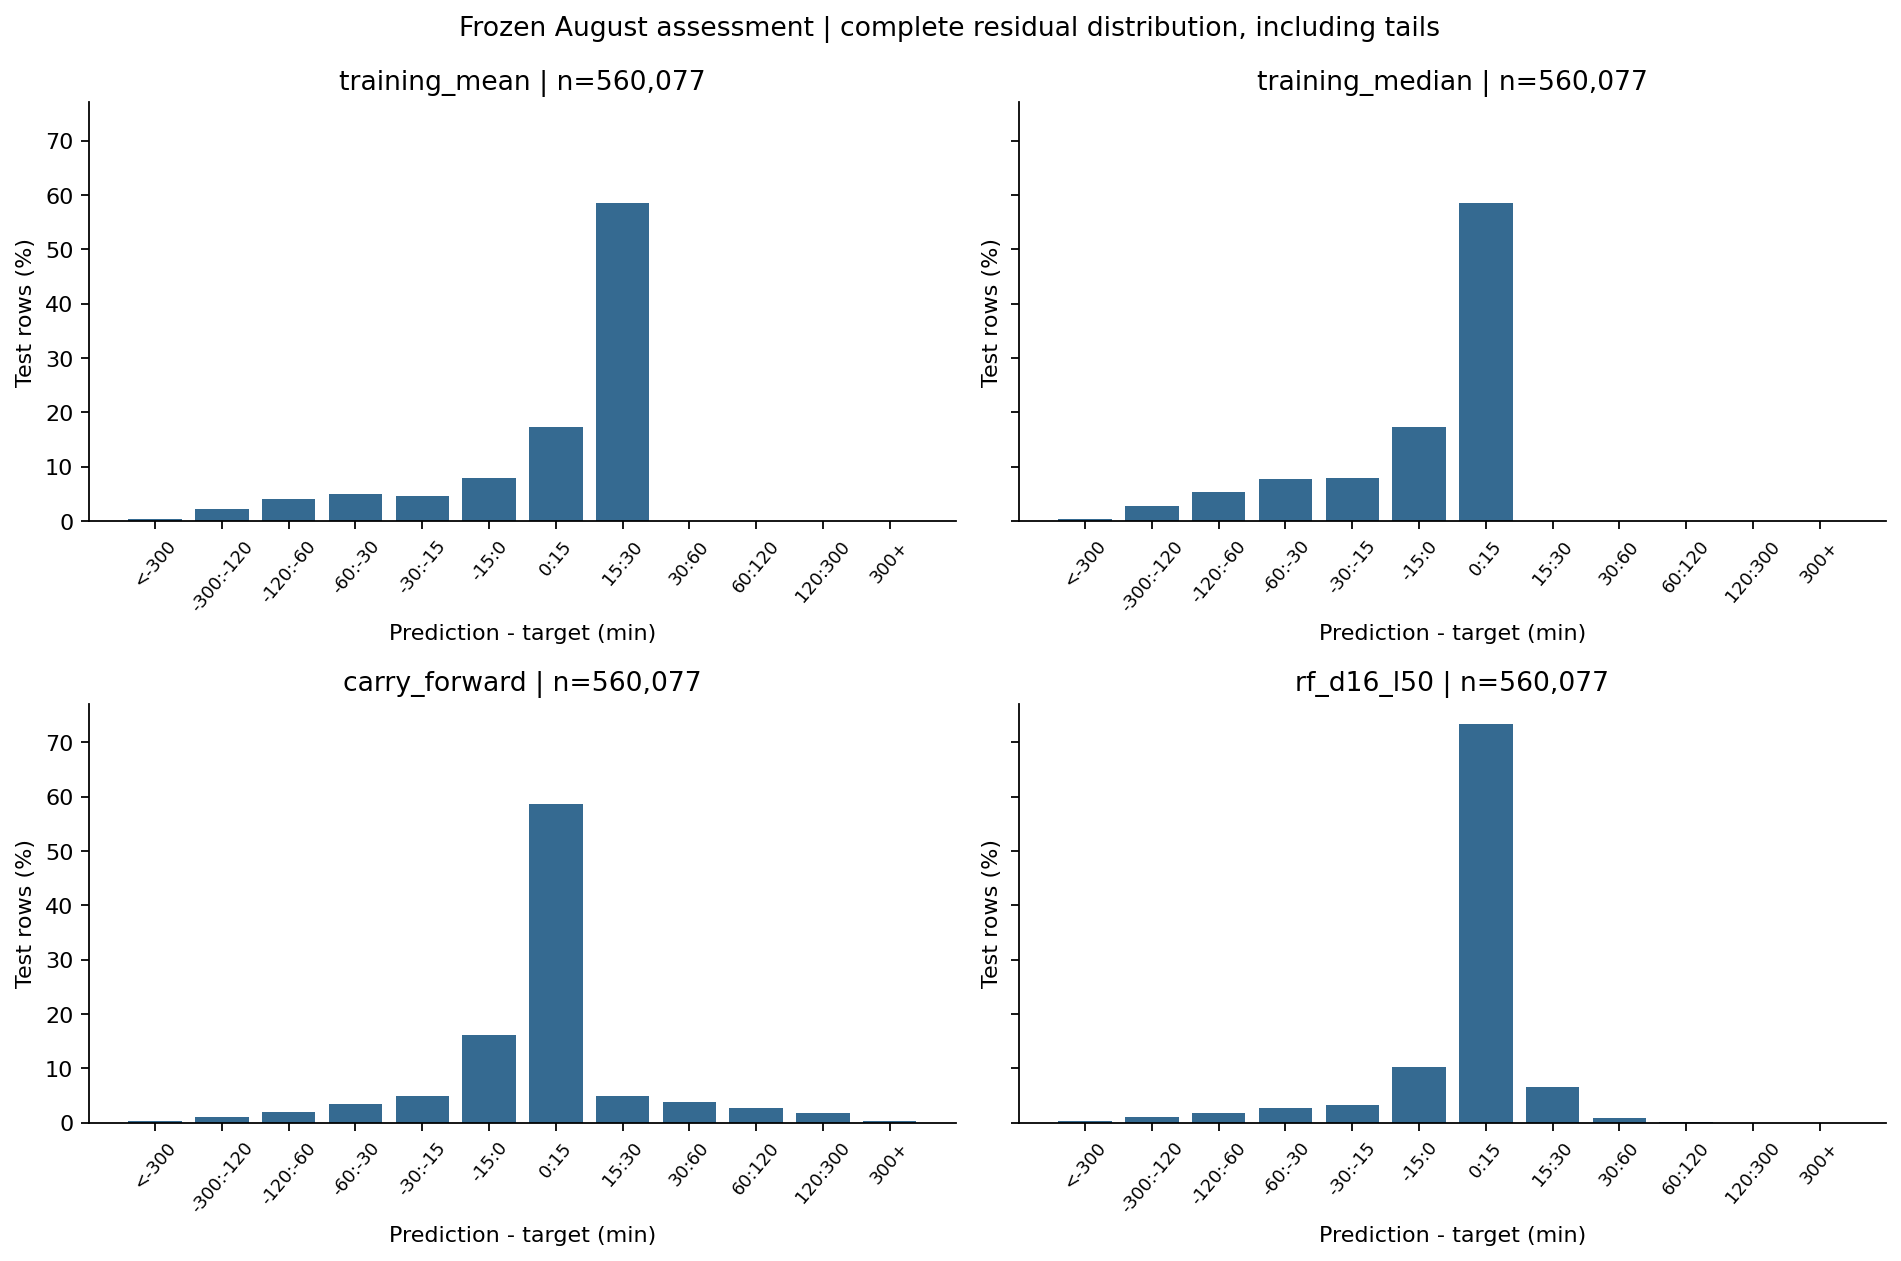

**[final_comparisons.csv](../experiments/runs/R0028/final_comparisons.csv)**：完整表 6 行；当前条件 6 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,reference_model,candidate_model,sample_scope
0,pooled,mae,560077,31,23.629809,13.655091,-9.974717,-10.863114,-9.040197,1000,minutes,training_mean,rf_d16_l50,final_test
1,pooled,rmse,560077,31,53.278497,42.917119,-10.361378,-12.541405,-8.017115,1000,minutes,training_mean,rf_d16_l50,final_test
2,pooled,mae,560077,31,17.999770,13.655091,-4.344678,-6.646804,-1.985018,1000,minutes,training_median,rf_d16_l50,final_test
3,pooled,rmse,560077,31,56.178116,42.917119,-13.260997,-16.165185,-10.050402,1000,minutes,training_median,rf_d16_l50,final_test
4,pooled,mae,560077,31,19.107376,13.655091,-5.452285,-7.555246,-3.782811,1000,minutes,carry_forward,rf_d16_l50,final_test
5,pooled,rmse,560077,31,59.972409,42.917119,-17.055290,-19.838116,-14.981383,1000,minutes,carry_forward,rf_d16_l50,final_test


**[final_comparison_training_mean.csv](../experiments/runs/R0028/final_comparison_training_mean.csv)**：完整表 2 行；当前条件 2 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,reference_model,candidate_model,sample_scope
0,pooled,mae,560077,31,23.629809,13.655091,-9.974717,-10.863114,-9.040197,1000,minutes,training_mean,rf_d16_l50,final_test
1,pooled,rmse,560077,31,53.278497,42.917119,-10.361378,-12.541405,-8.017115,1000,minutes,training_mean,rf_d16_l50,final_test


**[final_comparison_training_mean_daily.csv](../experiments/runs/R0028/final_comparison_training_mean_daily.csv)**：完整表 31 行；当前条件 31 行。

,date_utc,n,reference_absolute_error_sum,candidate_absolute_error_sum,reference_squared_error_sum,candidate_squared_error_sum
0,2026-08-01 00:00:00+00:00,18420,418912.696974,235353.819741,4.351076e+07,2.617767e+07
1,2026-08-02 00:00:00+00:00,17989,507357.226358,291490.484774,7.302860e+07,4.733442e+07
2,2026-08-03 00:00:00+00:00,18933,554125.952077,301306.551370,7.771293e+07,4.327671e+07
3,2026-08-04 00:00:00+00:00,18773,436747.636118,236378.308599,4.539280e+07,2.264067e+07
4,2026-08-05 00:00:00+00:00,17996,369711.768674,219496.657605,3.324670e+07,2.310456e+07
5,2026-08-06 00:00:00+00:00,17661,471770.957914,302357.063852,7.194178e+07,5.641629e+07
6,2026-08-07 00:00:00+00:00,17864,526123.635278,309455.000896,8.562784e+07,5.326840e+07
7,2026-08-08 00:00:00+00:00,16564,426975.613186,257982.335221,5.784860e+07,3.365991e+07
8,2026-08-09 00:00:00+00:00,17080,452672.019605,271285.274450,6.015890e+07,3.994041e+07
9,2026-08-10 00:00:00+00:00,18402,540383.766581,318779.936983,7.407433e+07,4.494550e+07


**[final_comparison_training_mean.png](../experiments/runs/R0028/figures/final_comparison_training_mean.png)**

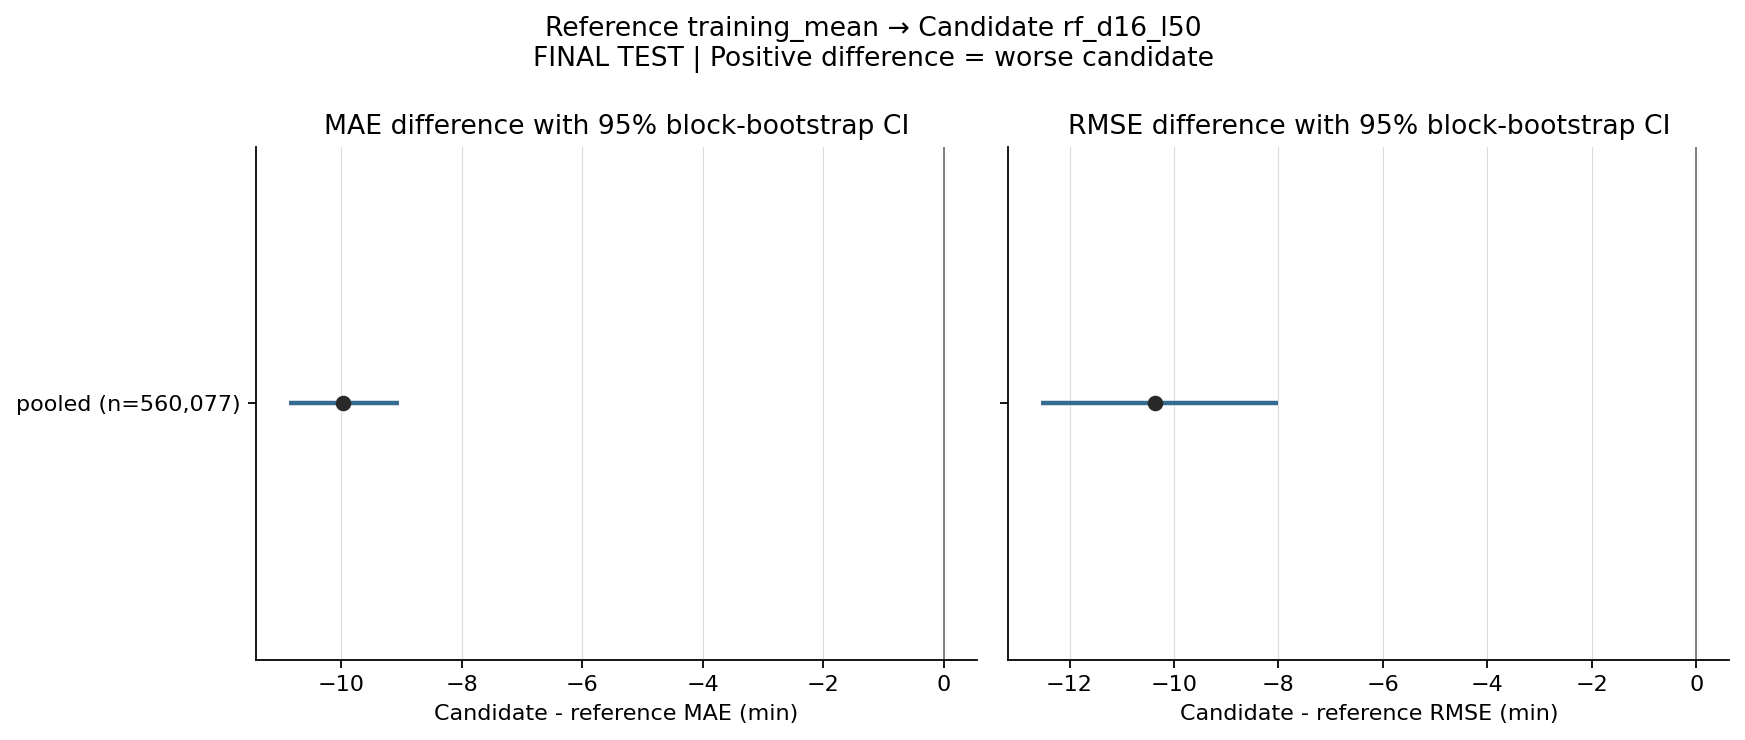

**[final_comparison_training_median.csv](../experiments/runs/R0028/final_comparison_training_median.csv)**：完整表 2 行；当前条件 2 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,reference_model,candidate_model,sample_scope
0,pooled,mae,560077,31,17.999770,13.655091,-4.344678,-6.646804,-1.985018,1000,minutes,training_median,rf_d16_l50,final_test
1,pooled,rmse,560077,31,56.178116,42.917119,-13.260997,-16.165185,-10.050402,1000,minutes,training_median,rf_d16_l50,final_test


**[final_comparison_training_median_daily.csv](../experiments/runs/R0028/final_comparison_training_median_daily.csv)**：完整表 31 行；当前条件 31 行。

,date_utc,n,reference_absolute_error_sum,candidate_absolute_error_sum,reference_squared_error_sum,candidate_squared_error_sum
0,2026-08-01 00:00:00+00:00,18420,342598.0,235353.819741,49697690.0,2.617767e+07
1,2026-08-02 00:00:00+00:00,17989,451540.0,291490.484774,82679846.0,4.733442e+07
2,2026-08-03 00:00:00+00:00,18933,498491.0,301306.551370,88588257.0,4.327671e+07
3,2026-08-04 00:00:00+00:00,18773,332757.0,236378.308599,51192025.0,2.264067e+07
4,2026-08-05 00:00:00+00:00,17996,256263.0,219496.657605,36870449.0,2.310456e+07
5,2026-08-06 00:00:00+00:00,17661,401126.0,302357.063852,80115434.0,5.641629e+07
6,2026-08-07 00:00:00+00:00,17864,472635.0,309455.000896,95959789.0,5.326840e+07
7,2026-08-08 00:00:00+00:00,16564,365436.0,257982.335221,65182084.0,3.365991e+07
8,2026-08-09 00:00:00+00:00,17080,393785.0,271285.274450,68244339.0,3.994041e+07
9,2026-08-10 00:00:00+00:00,18402,501232.0,318779.936983,85160646.0,4.494550e+07


**[final_comparison_training_median.png](../experiments/runs/R0028/figures/final_comparison_training_median.png)**

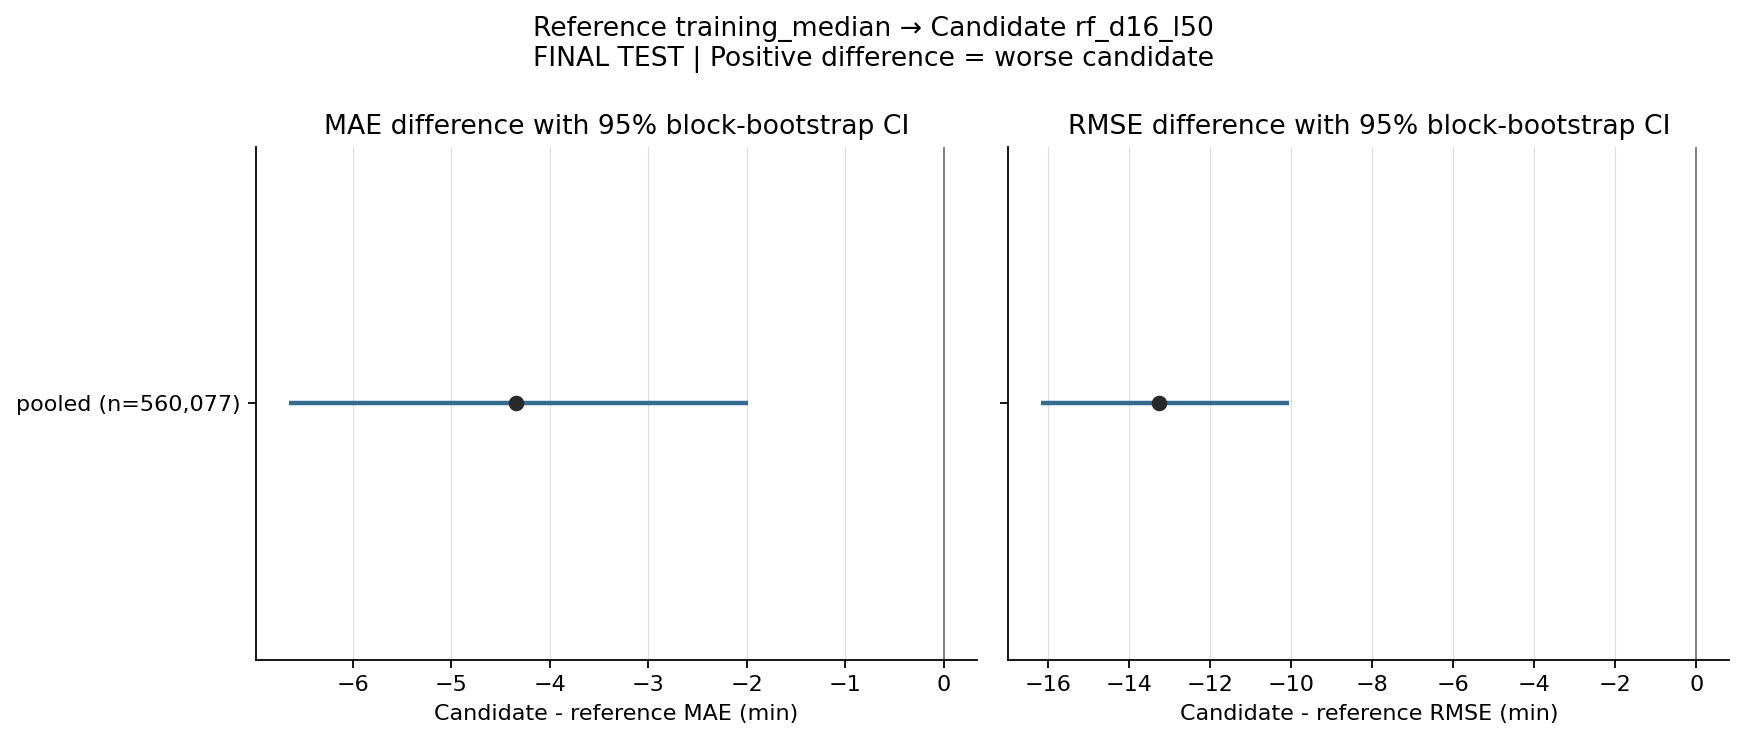

**[final_comparison_carry_forward.csv](../experiments/runs/R0028/final_comparison_carry_forward.csv)**：完整表 2 行；当前条件 2 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,reference_model,candidate_model,sample_scope
0,pooled,mae,560077,31,19.107376,13.655091,-5.452285,-7.555246,-3.782811,1000,minutes,carry_forward,rf_d16_l50,final_test
1,pooled,rmse,560077,31,59.972409,42.917119,-17.055290,-19.838116,-14.981383,1000,minutes,carry_forward,rf_d16_l50,final_test


**[final_comparison_carry_forward_daily.csv](../experiments/runs/R0028/final_comparison_carry_forward_daily.csv)**：完整表 31 行；当前条件 31 行。

,date_utc,n,reference_absolute_error_sum,candidate_absolute_error_sum,reference_squared_error_sum,candidate_squared_error_sum
0,2026-08-01 00:00:00+00:00,18420,308350.0,235353.819741,50930484.0,2.617767e+07
1,2026-08-02 00:00:00+00:00,17989,400819.0,291490.484774,76065803.0,4.733442e+07
2,2026-08-03 00:00:00+00:00,18933,472150.0,301306.551370,92709088.0,4.327671e+07
3,2026-08-04 00:00:00+00:00,18773,375119.0,236378.308599,64348737.0,2.264067e+07
4,2026-08-05 00:00:00+00:00,17996,280586.0,219496.657605,45932614.0,2.310456e+07
5,2026-08-06 00:00:00+00:00,17661,404969.0,302357.063852,82762543.0,5.641629e+07
6,2026-08-07 00:00:00+00:00,17864,518911.0,309455.000896,113383927.0,5.326840e+07
7,2026-08-08 00:00:00+00:00,16564,428785.0,257982.335221,88757947.0,3.365991e+07
8,2026-08-09 00:00:00+00:00,17080,398332.0,271285.274450,72179188.0,3.994041e+07
9,2026-08-10 00:00:00+00:00,18402,484071.0,318779.936983,90854471.0,4.494550e+07


**[final_comparison_carry_forward.png](../experiments/runs/R0028/figures/final_comparison_carry_forward.png)**

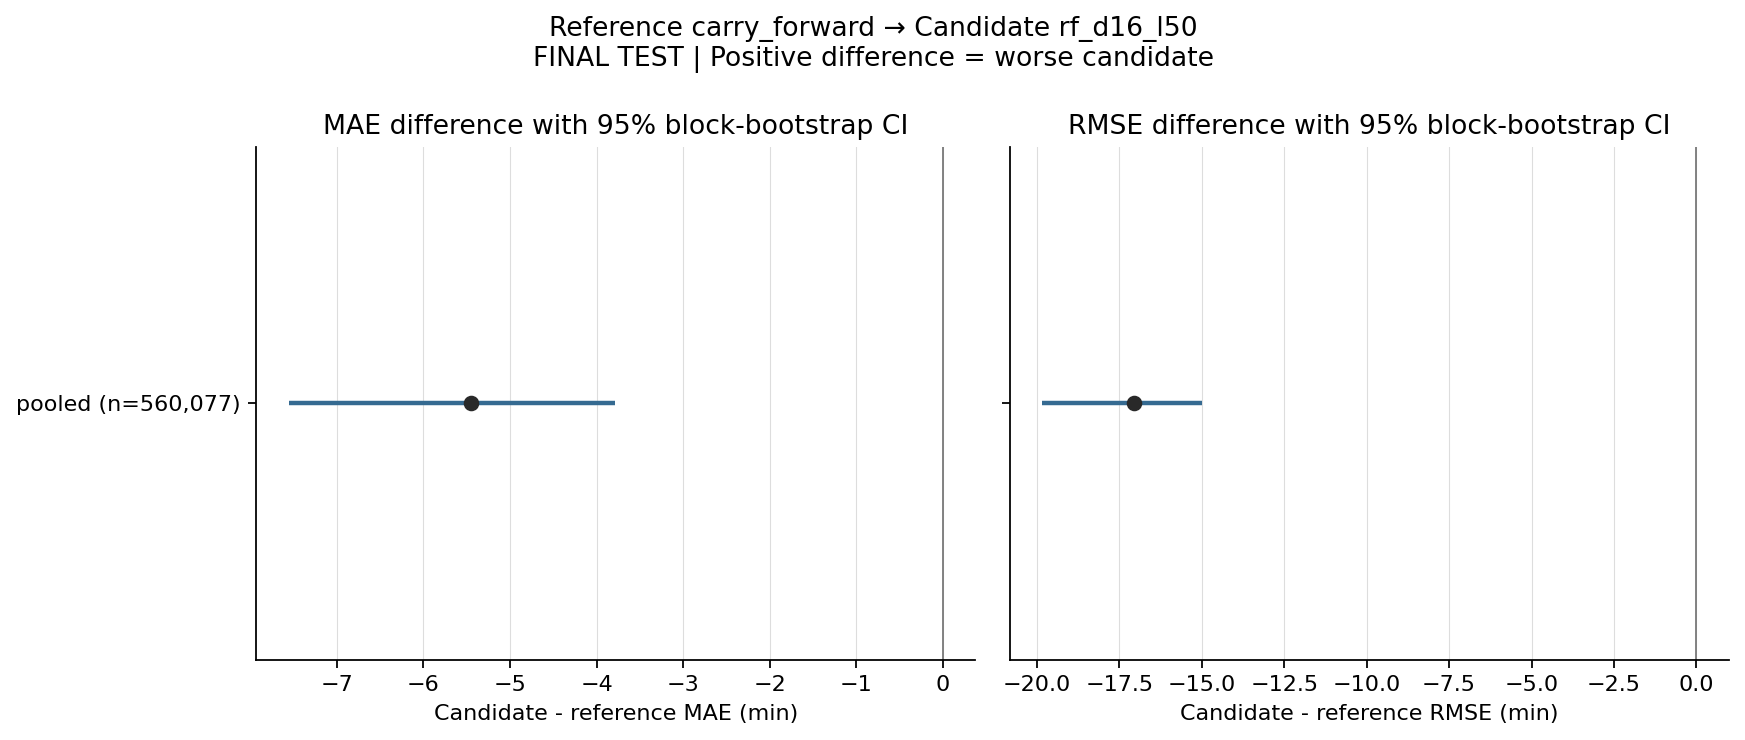

In [7]:
archived_table("residual_summary.csv", limit=None)
archived_image("figures/final_residual_distribution.png")
archived_table("final_comparisons.csv", limit=None)
for baseline in ["training_mean", "training_median", "carry_forward"]:
    archived_table(f"final_comparison_{baseline}.csv", limit=None)
    archived_table(f"final_comparison_{baseline}_daily.csv", limit=None)
    archived_image(f"figures/final_comparison_{baseline}.png")

## 6. 最终完整 EDA 与 RQ1：固定开发参考的机场描述

下方完整单航段 EDA 仅读取最终 RQ1 运行已生成的表和图，不重新读取目标数据。最终机场分析应复用开发期冻结的 A/C/w，不根据 8 月重新选择共同支持。每次标准化平均 \(\Delta\) 与累计 \(S_+,S_-,S_{net}\) 保持不同单位。这里的机场差异和网络流量是描述性结果，不证明机场造成了延误或恢复。

In [8]:
notice(f"**RQ1 结果归档：{RQ1_RUN_DIR.name}**")
single_flight_eda(RQ1_RUN_DIR)
archived_json("rq1_complete_summary.json", base=RQ1_RUN_DIR)
standard = archived_json("rq1_standardized/rq1_standardization_summary.json", base=RQ1_RUN_DIR)
if standard is not None:
    notice("冻结参考复用状态：**" + ("归档声明已复用" if standard.get("frozen_reference_reused") else "未归档为已复用") + "**。")
rq1_reference(RQ1_RUN_DIR)
rq1_reference_identity(RQ1_RUN_DIR)
archived_table("rq1_standardized/selection_attempts.csv", base=RQ1_RUN_DIR, limit=None)
archived_table("rq1_standardized/rq1_airports.csv", base=RQ1_RUN_DIR, limit=None, filters={"threshold": "ge15"})
archived_table("rq1_standardized/rq1_threshold_stability.csv", base=RQ1_RUN_DIR, limit=None)
archived_table("rq1_standardized/rq1_airports_monthly.csv", base=RQ1_RUN_DIR)
archived_table("rq1_standardized/network_nodes.csv", base=RQ1_RUN_DIR)
archived_table("rq1_standardized/network_edges.csv", base=RQ1_RUN_DIR)
for name in ["rq1_standardized_airports.png", "rq1_threshold_stability.png", "rq1_network_geographic.png", "rq1_cumulative_delay.png"]:
    archived_image("figures/" + name, base=RQ1_RUN_DIR)

**RQ1 结果归档：R0028**

**完整单航段 EDA 来源：R0028**

**未归档：eda_complete_summary.json**（tables）。

**未归档：single_flight_delay_stats.csv**（tables）。

**未归档：single_flight_operations.csv**（tables）。

...

**未归档：network_edges.csv**（rq1_standardized）。

**未归档图：rq1_standardized_airports.png**。

**未归档图：rq1_threshold_stability.png**。

**未归档图：rq1_network_geographic.png**。

**未归档图：rq1_cumulative_delay.png**。

## 7. 可重复核对与结论边界

共享工具 `scripts/final_evaluation.py --verify-run <run目录>` 可以从已保存预测重算指标、核对产物哈希及可用访问账本，不重新训练或读取原始测试数据。本 Notebook 不自动调用该工具、不把未经运行的核对写成已通过。测试结果只能用于报告冻结候选的表现；若之后修改方法，应明确记为测试后探索，不能继续把 8 月当作未见数据。